# Information gained from the first cycles

Vary the observed prefix while holding the cohort and future scoring window fixed.
Each landmark has its own model fits, so the errors reflect both the available
observations and the predictor fitted at that landmark.

In [1]:
from pathlib import Path
import sys
import os
from datetime import datetime, timezone
os.environ.setdefault("LIQ_FINAL_DEVICE", os.environ.get("LIQ_DEVICE", "cpu"))
os.environ.setdefault("LIQ_DEVICE", os.environ["LIQ_FINAL_DEVICE"])
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "pyproject.toml").is_file() and (p / "src/dpi_evt").is_dir())
for directory in (ROOT / "src", ROOT / "external_validation", ROOT / "scripts"):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))
import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11,
                     "font.family": "DejaVu Sans", "axes.grid": True, "grid.alpha": .2})
COLORS = {"DPI-EVT":"#246aac", "DPI-EVT +A":"#1b9e8a", "EVT-NeuralSSM":"#69788a",
          "Transformer +cummax":"#c17a24", "Transformer matched +A/crossing loss":"#8658a6",
          "GP prefix (linear + SE)":"#8469a5", "Threshold-projected Transformer/GBM":"#777777",
          "Time-warped Transformer/GBM":"#b685b3", "GBM horizon mixture":"#a66c20", "Cox PH":"#555555"}
TABLES = ROOT / "results/tables"
print("Executed:", datetime.now(timezone.utc).isoformat(timespec="seconds"))
print("Inputs: included aggregate tables and public external extracts")

Executed: 2026-11-06T14:06:56+00:00
Inputs: included aggregate tables and public external extracts


## Common-cohort prefix comparison

,N0,model,event_log_err,traj_rmse_continuation
0,0,DPI-EVT,0.7391,0.1407
1,0,Transformer +cummax,1.3123,0.1289
2,0,GP prefix (linear + SE),3.2501,0.6274
3,3,DPI-EVT,0.5853,0.1354
4,3,Transformer +cummax,1.2918,0.1148
5,3,GP prefix (linear + SE),3.2344,0.5100
6,5,DPI-EVT,0.5379,0.1322
7,5,Transformer +cummax,1.0238,0.1090
8,5,GP prefix (linear + SE),3.1822,0.4776
9,10,DPI-EVT,0.4878,0.1255


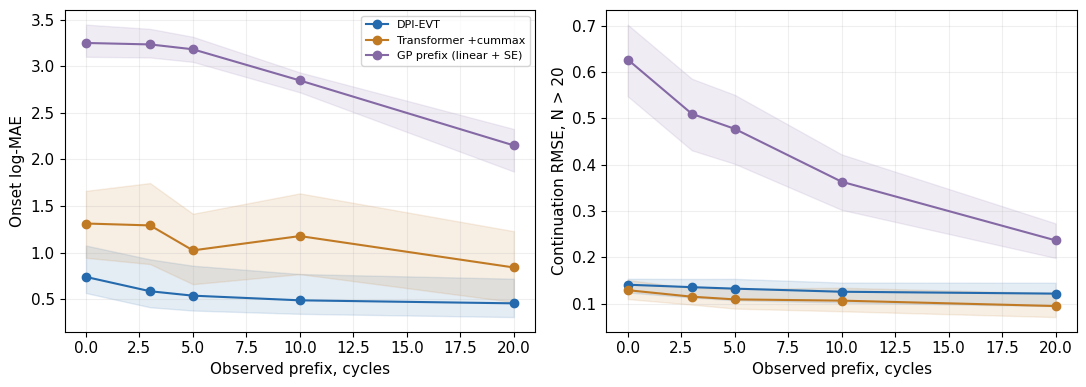

DPI-EVT onset reduction: 38.4%
DPI-EVT curve reduction: 13.7%


In [2]:
prefix = pd.read_csv(TABLES / "prefix_summary.csv")
models=["DPI-EVT","Transformer +cummax","GP prefix (linear + SE)"]
display(prefix[["N0","model","event_log_err","traj_rmse_continuation"]].round(4))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for name in models:
    d=prefix[prefix.model.eq(name)].sort_values("N0")
    for ax,key,label in zip(axes,["event_log_err","traj_rmse_continuation"],["Onset log-MAE","Continuation RMSE, N > 20"]):
        ax.plot(d.N0,d[key],"o-",color=COLORS[name],label=name)
        ax.fill_between(d.N0,d[key+"_lo"],d[key+"_hi"],color=COLORS[name],alpha=.12)
        ax.set(xlabel="Observed prefix, cycles",ylabel=label)
axes[0].legend(fontsize=8);fig.tight_layout();plt.show()
g=prefix[prefix.model.eq("DPI-EVT")].set_index("N0")
print("DPI-EVT onset reduction:", f"{1-g.loc[20,'event_log_err']/g.loc[0,'event_log_err']:.1%}")
print("DPI-EVT curve reduction:", f"{1-g.loc[20,'traj_rmse_continuation']/g.loc[0,'traj_rmse_continuation']:.1%}")

## Interpretation

Early observations help every evaluated model family. The primary ten-cycle experiment and the common-cohort prefix experiment use different eligible training cohorts and scoring windows, so their ten-cycle errors come from different fitted models.